Sara Rezaei

In [1]:
import torch
from torch.utils.data import DataLoader, Dataset
import torchvision
import torchvision.transforms as transforms
from torch.utils.data.sampler import SubsetRandomSampler
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
#set gpu
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


FashionMNIST dataset is ready to use in torch visions datasets and it can be imported directly from the library.

In [3]:
train_set = torchvision.datasets.FashionMNIST("./data", download=True, train=True,
                                              transform=transforms.Compose([transforms.ToTensor()]))
test_set = torchvision.datasets.FashionMNIST("./data", download=True, train=False,
                                             transform=transforms.Compose([transforms.ToTensor()]))

100%|██████████| 26.4M/26.4M [00:02<00:00, 11.0MB/s]


Extracting ./data/FashionMNIST/raw/train-images-idx3-ubyte.gz to ./data/FashionMNIST/raw



100%|██████████| 29.5k/29.5k [00:00<00:00, 173kB/s]


Extracting ./data/FashionMNIST/raw/train-labels-idx1-ubyte.gz to ./data/FashionMNIST/raw



100%|██████████| 4.42M/4.42M [00:01<00:00, 3.33MB/s]


Extracting ./data/FashionMNIST/raw/t10k-images-idx3-ubyte.gz to ./data/FashionMNIST/raw



100%|██████████| 5.15k/5.15k [00:00<00:00, 6.30MB/s]

Extracting ./data/FashionMNIST/raw/t10k-labels-idx1-ubyte.gz to ./data/FashionMNIST/raw



splitting dataset to train set and valid set using random split

In [4]:
batch_size = 32
train_loader = DataLoader(train_set, batch_size=batch_size , shuffle = True)
test_loader = DataLoader(test_set, batch_size=batch_size , shuffle = False)

In [5]:
print("The train set contains {} images, in {} batches".format(len(train_loader), len(train_loader)))
print("The test set contains {} images, in {} batches".format(len(test_loader), len(test_loader)))

The train set contains 1875 images, in 1875 batches
The test set contains 313 images, in 313 batches


Visualize Dataset

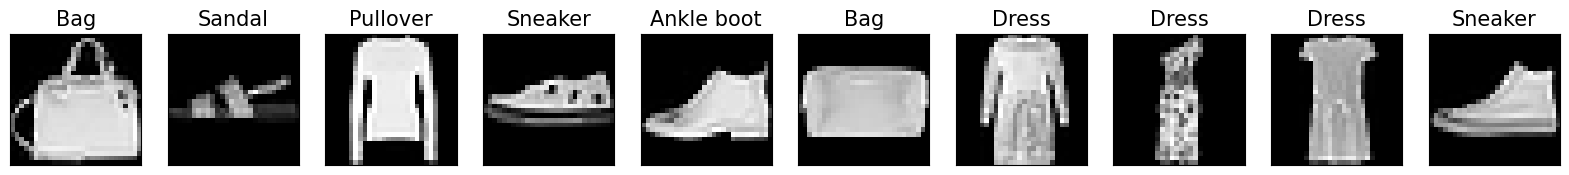

In [6]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm

nsamples=10
classes_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal','Shirt', 'Sneaker', 'Bag', 'Ankle boot']
imgs, labels = next(iter(train_loader))

fig=plt.figure(figsize=(20,5),facecolor='w')
for i in range(nsamples):
    ax = plt.subplot(1,nsamples, i+1)
    plt.imshow(imgs[i, 0, :, :], vmin=0, vmax=1.0, cmap=cm.gray)
    ax.set_title("{}".format(classes_names[labels[i]]), fontsize=15)
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

plt.savefig('fashionMNIST_samples.png', bbox_inches='tight')
plt.show()

**Initialize the arguments**

In [7]:
latent_dim = 100
channels = 1
epochs = 15
lr = 0.0002
beta1 = 0.5

In [8]:
class Generator(nn.Module):
    def __init__(self, latent_dim, channels):
        super(Generator, self).__init__()

        self.model = nn.Sequential(
            nn.Linear(in_features=latent_dim, out_features=128*7*7),
            nn.ReLU(inplace=True),
            nn.Unflatten(dim=1, unflattened_size=(128, 7, 7)),

            nn.Upsample(scale_factor=2),

            nn.Conv2d(in_channels=128, out_channels=128, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(num_features=128, momentum=0.8),
            nn.ReLU(inplace=True),

            nn.Upsample(scale_factor=2),

            nn.Conv2d(in_channels=128, out_channels=64, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(num_features=64, momentum=0.8),
            nn.ReLU(inplace=True),

            nn.Conv2d(in_channels=64, out_channels=channels, kernel_size=3, stride=1, padding=1),
            nn.ReLU(inplace=True)
        )

    def forward(self, z):
        return self.model(z)

In [9]:
class Discriminator(nn.Module):
    def __init__(self, channels):
        super(Discriminator, self).__init__()

        self.features = nn.Sequential(
            nn.Conv2d(in_channels=channels, out_channels=32, kernel_size=3, stride=2, padding=1), #14x14
            nn.LeakyReLU(negative_slope=0.2, inplace=True),
            nn.Dropout(p=0.25),

            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=2, padding=1), #7x7
            nn.BatchNorm2d(num_features=64),
            nn.LeakyReLU(negative_slope=0.2, inplace=True),
            nn.Dropout(p=0.25),

            nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, stride=2, padding=1), #4x4
            nn.BatchNorm2d(num_features=128),
            nn.LeakyReLU(negative_slope=0.2, inplace=True),
            nn.Dropout(p=0.25),

            nn.Conv2d(in_channels=128, out_channels=256, kernel_size=3, stride=1, padding=1), #4x4
            nn.BatchNorm2d(num_features=256),
            nn.LeakyReLU(negative_slope=0.2, inplace=True),
            nn.Dropout(p=0.25)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=4*4*256, out_features=1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.classifier(self.features(x))

In [10]:
# Loss function
adversarial_loss = nn.BCELoss()

generator = Generator(latent_dim, channels).to(device)
discriminator = Discriminator(channels).to(device)

# Optimizers
optimizer_G = torch.optim.Adam(generator.parameters(), lr=lr, betas=(beta1, 0.999))
optimizer_D = torch.optim.Adam(discriminator.parameters(), lr=lr, betas=(beta1, 0.999))

**Train Model**

In [11]:
for epoch in range(epochs):
    for (imgs, _) in train_loader:

        valid = torch.ones((imgs.size(0), 1)).to(device)
        fake = torch.zeros((imgs.size(0), 1)).to(device)

        real_imgs = imgs.to(device)
        z = torch.randn((batch_size, latent_dim)).to(device)

        # Train Generator
        optimizer_G.zero_grad()
        gen_imgs = generator(z)
        g_loss = adversarial_loss(discriminator(gen_imgs), valid)
        g_loss.backward()
        optimizer_G.step()

        # Train Discriminator
        optimizer_D.zero_grad()
        real_loss = adversarial_loss(discriminator(real_imgs), valid)
        fake_loss = adversarial_loss(discriminator(gen_imgs.detach()), fake)
        d_loss = (real_loss + fake_loss) / 2
        d_loss.backward()
        optimizer_D.step()


    print(f'Epoch: {epoch+1} Loss Dis: {d_loss.item():.5f}')
    print(f'Epoch: {epoch+1} Loss Gen: {g_loss.item():.5f}')


Epoch: 1 Loss Dis: 0.25565
Epoch: 1 Loss Gen: 2.29279
Epoch: 2 Loss Dis: 0.35725
Epoch: 2 Loss Gen: 1.24036
Epoch: 3 Loss Dis: 0.38058
Epoch: 3 Loss Gen: 1.58416
Epoch: 4 Loss Dis: 0.40637
Epoch: 4 Loss Gen: 2.19150
Epoch: 5 Loss Dis: 0.44400
Epoch: 5 Loss Gen: 1.16779
Epoch: 6 Loss Dis: 0.16187
Epoch: 6 Loss Gen: 3.11068
Epoch: 7 Loss Dis: 0.27587
Epoch: 7 Loss Gen: 1.49160
Epoch: 8 Loss Dis: 0.33288
Epoch: 8 Loss Gen: 2.22072
Epoch: 9 Loss Dis: 0.22795
Epoch: 9 Loss Gen: 2.09624
Epoch: 10 Loss Dis: 0.24568
Epoch: 10 Loss Gen: 1.90175
Epoch: 11 Loss Dis: 0.10481
Epoch: 11 Loss Gen: 2.65991
Epoch: 12 Loss Dis: 0.12832
Epoch: 12 Loss Gen: 2.09066
Epoch: 13 Loss Dis: 0.35225
Epoch: 13 Loss Gen: 1.67611
Epoch: 14 Loss Dis: 0.18924
Epoch: 14 Loss Gen: 5.07608
Epoch: 15 Loss Dis: 0.36057
Epoch: 15 Loss Gen: 4.19449


**Test Model**

In [13]:
noise= torch.randn((batch_size , 100)).to(device)
generated_data = generator(noise)

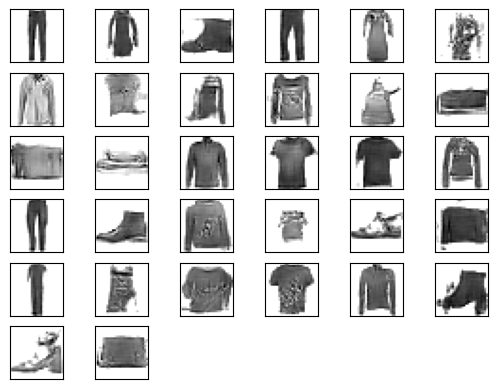

In [14]:
generated_data = generated_data.cpu().detach()

for i in range(32):
    ax = plt.subplot(6, 6, i + 1)
    plt.imshow(generated_data[i].squeeze(), cmap="gray_r")
    plt.xticks([])
    plt.yticks([])